# EO Spatial Split Planner — random patches and segmentation

Sample **rectangular image patches at random positions in both spatial axes**, estimate a separation from the B05 variogram, and train a small semantic-segmentation CNN with and without excluding nearby training patches. Both models are evaluated on exactly the same validation and test patches. A third condition matches the buffered training-patch count without enforcing separation.

The primary experiment uses real **2021 Sentinel-2 imagery and ESA WorldCover 2021 labels**, avoiding a year mismatch. The [variogram procedure](PROCEDURE.md) follows the selected subset of the frozen [reference checkpoint `ac7dfc6`](https://github.com/stefanopitton/lulc-classification/blob/ac7dfc6578c2c408c87398e15073354752bbd32b/src/lulc/validation/autocorrelation.py). This remains a draft demo: the objective is to measure separation, retained training support and actual prediction behavior, without assuming that buffering must increase a score.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from IPython.display import Image, JSON, Markdown, display

_here=Path.cwd()
REPO_ROOT=next(p for p in [_here,_here / "agentic-eo",*_here.parents]
               if (p / "lib" / "agentic_eo").is_dir())
TOOL_ROOT=REPO_ROOT / "examples" / "eo-spatial-split-planner"
ARTIFACTS=TOOL_ROOT / "artifacts"
DATA_DIR=ARTIFACTS / "segmentation_data"
BENCHMARK_DIR=ARTIFACTS / "segmentation_benchmark"
sys.path.insert(0,str(TOOL_ROOT))
import server as planner
from run_segmentation import load_demo_data, run_demo


## Matched-year satellite features and reference labels

The Berlin AOI is preserved. Features are calibrated surface reflectance in **B05, B03, B04 and B08**, on B05's native projected **20 m** grid. The 10 m bands are averaged to that grid; SCL is aligned by nearest neighbor, and only classes 4/5/6 are retained. ESA WorldCover 2021 v200 labels are aligned by nearest neighbor to the same grid and mapped to vegetation, built-up and water. Other labels are ignored.

WorldCover is a **weak annual reference**, produced by a classifier using Sentinel-1 and Sentinel-2. These scores measure agreement with that reference, not independently surveyed accuracy. Annual labels may also differ from the land cover on the acquisition date.

`RECOMPUTE_IMAGES=False` reuses the saved numeric GeoTIFFs; missing inputs trigger real public-STAC acquisition. `TRAIN_MODELS=True` actually trains all conditions when this notebook runs, using cached imagery and no pretrained weights.


In [2]:
RECOMPUTE_IMAGES=False
TRAIN_MODELS=True
BBOX=[13.30,52.35,13.50,52.50]
START_DATE,END_DATE="2021-06-01","2021-08-31"
BAND="B05"
SPLIT_SEED,MODEL_SEED=3,42
PATCH_SIZE_PIXELS=[48,64]
N_PATCHES=40
TRAINING_STEPS=150
BUFFER_M=None  # measure a sufficient guard from this 2021 B05 field
VARIOGRAM_OPTIONS={"n_bins":24,"n_pairs_per_lag":200_000,"max_lag_m":12_800.0}

expected_inputs=[DATA_DIR / name for name in (
    "sentinel2_reflectance_20m.tif","worldcover_2021_20m.tif","manifest.json")]
if RECOMPUTE_IMAGES or not all(p.exists() for p in expected_inputs):
    from segmentation_data import fetch_segmentation_data
    fetch_segmentation_data(DATA_DIR,bbox=BBOX,start_date=START_DATE,end_date=END_DATE,
                            force=RECOMPUTE_IMAGES)
values,labels,profile,resolution_m,manifest=load_demo_data(DATA_DIR)
feature_path=DATA_DIR / "sentinel2_reflectance_20m.tif"
display(JSON({"request":manifest["request"],"shape":manifest["shape"],
              "bands":manifest["band_names"],"pixel_size_m":resolution_m,
              "sentinel2":manifest["sentinel2"],"worldcover":manifest["worldcover"],
              "label_caveat":manifest["label_caveat"]}))


<IPython.core.display.JSON object>

## Random rectangles and a paired comparison

Forty nonoverlapping **48 × 64 pixel rectangles** (960 × 1,280 m) are sampled using seed 3. Placement cells prevent overlap, with random cell selection and jitter in both row and column. Split assignment is seeded without class stratification. The supplied finite-pixel mask already includes imagery and reference-availability exclusions; vegetation/built-up/water identities do not choose placement. Candidate assignment is 24 training, 8 validation and 8 test patches.

Buffering removes **whole rectangles** rather than cropping their edges. Test patches have priority, followed by validation and training. In this experiment 6 validation and 8 test patches survive and are held fixed across every model condition. The paired condition without a training buffer restores all 24 candidate training patches; the buffered condition retains 8. The additional size-matched control randomly chooses 8 training rectangles without a distance filter. It matches patch count, while labelled pixel counts and class composition can still differ.


In [3]:
report_path=BENCHMARK_DIR / "segmentation_report.json"
if TRAIN_MODELS or not report_path.exists():
    segmentation_report=run_demo(
        data_dir=DATA_DIR,output_dir=BENCHMARK_DIR,buffer_m=BUFFER_M,
        split_seed=SPLIT_SEED,model_seed=MODEL_SEED,steps=TRAINING_STEPS,
        max_pairs_per_lag=VARIOGRAM_OPTIONS["n_pairs_per_lag"],
    )
else:
    segmentation_report=json.loads(report_path.read_text())
patch_plan=json.loads((BENCHMARK_DIR / "benchmark_plan.json").read_text())
LAG_M=float(segmentation_report["buffer_m"])
with rasterio.open(BENCHMARK_DIR / "unbuffered_patch_split.tif") as src:
    unbuffered_mask=src.read(1)
with rasterio.open(BENCHMARK_DIR / "buffered_patch_split.tif") as src:
    buffered_mask=src.read(1)
display(JSON({key:patch_plan[key] for key in (
    "method","seed","patch_size_pixels","n_candidate_patches","patch_counts",
    "requested_buffer_m","recommended_buffer_m","buffer_source","buffer_priority",
    "paired_comparison","buffer_autocorrelation","splits","spatial_diagnostics",
    "unbuffered_baseline","warnings") if key in patch_plan}))


<IPython.core.display.JSON object>

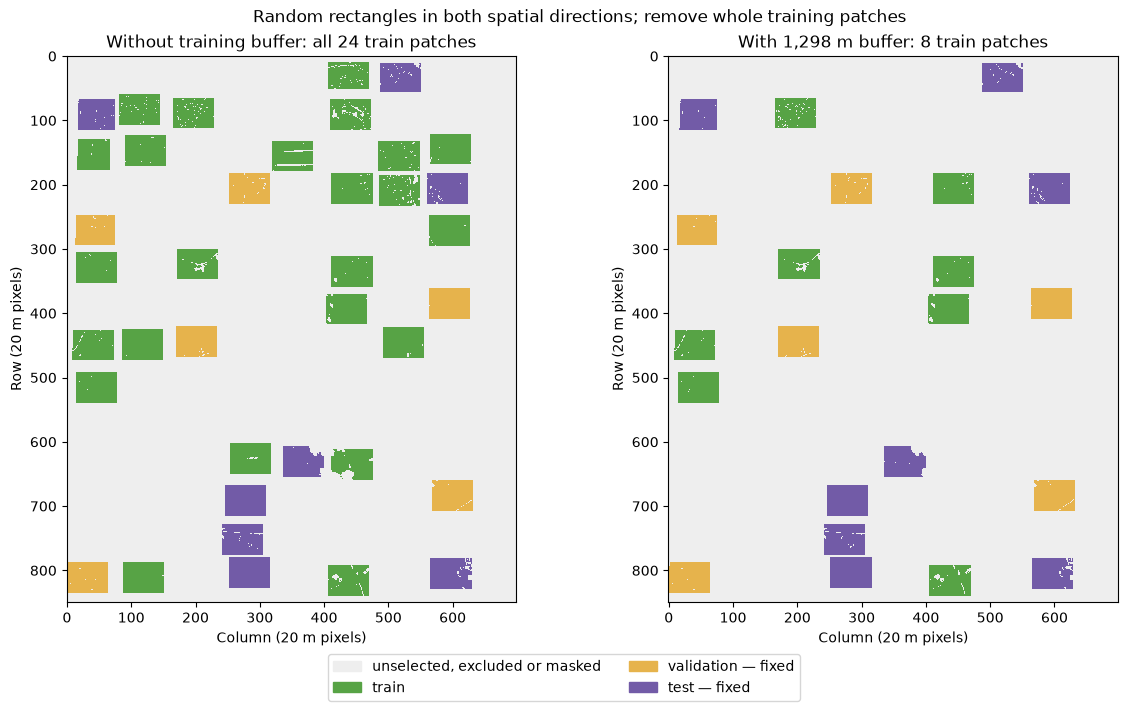

<IPython.core.display.JSON object>

In [4]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

split_palette=ListedColormap(["#eeeeee","#57a345","#e6b34c","#725ba7"])
fig,axes=plt.subplots(1,2,figsize=(12,7),layout="constrained")
for ax,mask,title in zip(axes,(unbuffered_mask,buffered_mask),(
    "Without training buffer: all 24 train patches",
    f"With {LAG_M:,.0f} m buffer: 8 train patches")):
    ax.imshow(mask,cmap=split_palette,norm=BoundaryNorm(np.arange(-.5,4.5),4),interpolation="nearest")
    ax.set(title=title,xlabel="Column (20 m pixels)",ylabel="Row (20 m pixels)")
legend=[Patch(color=split_palette.colors[i],label=name) for i,name in enumerate((
    "unselected, excluded or masked","train","validation — fixed","test — fixed"))]
fig.legend(handles=legend,loc="outside lower center",ncol=2)
fig.suptitle("Random rectangles in both spatial directions; remove whole training patches")
plt.show()
display(JSON({"validation_pixel_locations_identical":bool(np.array_equal(unbuffered_mask==2,buffered_mask==2)),
              "test_pixel_locations_identical":bool(np.array_equal(unbuffered_mask==3,buffered_mask==3)),
              "buffered_train_is_subset":bool(np.all((buffered_mask!=1)|(unbuffered_mask==1)))}))


## Variogram procedure

The AOI is one realization of a random field. Use the continuous values as read, without normalization, and calculate float64 population variance over finite pixels. Zero or non-finite variance is invalid.

Build 24 logarithmic bins from the native resolution to 12,800 m, using geometric centers. Draw 200,000 offsets per source bin with uniform angle and uniform radius inside that bin. Round to integer pixel offsets, discard zero offsets, and **reassign every pair to the bin containing its actual rounded distance**. Draw anchors uniformly over the raster; discard out-of-bounds partners and pairs touching non-finite values. Thus accepted counts vary by bin and need not equal the number of attempted draws.

For each destination bin, accumulate counts and squared differences in float64:

\[
\gamma(h) = \frac{\sum (z_i-z_j)^2}{2\,n_h},\qquad
\rho(h) = 1 - \frac{\gamma(h)}{\operatorname{var}(z)}.
\]

Empty bins remain missing. Negative rho values are retained. Fit only the spherical model to at least four populated bins, with nonnegative coefficients and `sigma = 1/sqrt(counts)`:

\[
\gamma_{\mathrm{sph}}(h) = c_0 + c_1(1.5t-0.5t^3),\qquad
 t=\min(h/a,1).
\]

`c0` is nugget, `c1` is partial sill, **total sill is `c0+c1`**, and `a` is practical range. Report residual sum of squares. The upstream reference names its second model coefficient `sill`; this tool distinguishes partial and total sill explicitly. No directional Pearson, covariance curve, Moran's I, Geary's C or exponential model is computed.


## Evaluate the measured lag on the actual B05 pixels

The requested lag below is the guard selected from this 2021 scene. B05 occupies band 1 of the four-band feature GeoTIFF. Rho is interpolated linearly in **log-distance**, after excluding empty bins. Acceptance requires **`rho_at_lag < 0.1` AND `lag_m >= practical_range_m`** with a resolved spherical fit.

`buffer_autocorrelation` in a split report checks the actual guard separately from an optional query lag. A passing query at a larger separation cannot endorse a smaller guard.


In [5]:
evaluation=planner.evaluate_spatial_autocorrelation(
    raster_path=str(feature_path),band_index=1,band=BAND,lag_m=LAG_M,
    seed=SPLIT_SEED,**VARIOGRAM_OPTIONS)
if evaluation.get("status")!="ok":
    raise RuntimeError(evaluation.get("error",evaluation))
summary_keys=("estimator","lag_m","rho_at_lag","practical_range_m","nugget","partial_sill",
              "sill","fit_rss","fit_status","variance","nan_fraction","seed",
              "n_pairs_per_lag","decision","warnings")
display(JSON({key:evaluation[key] for key in summary_keys if key in evaluation}))
display(JSON({"per_bin_diagnostics":[
    {"lag_lo_m":lo,"lag_hi_m":hi,"lag_center_m":h,"valid_pair_count":n,"gamma":g,"rho":r}
    for lo,hi,h,n,g,r in zip(evaluation["lag_edges_m"][:-1],evaluation["lag_edges_m"][1:],
                            evaluation["lag_centers_m"],evaluation["counts"],
                            evaluation["gamma"],evaluation["rho"])]}))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

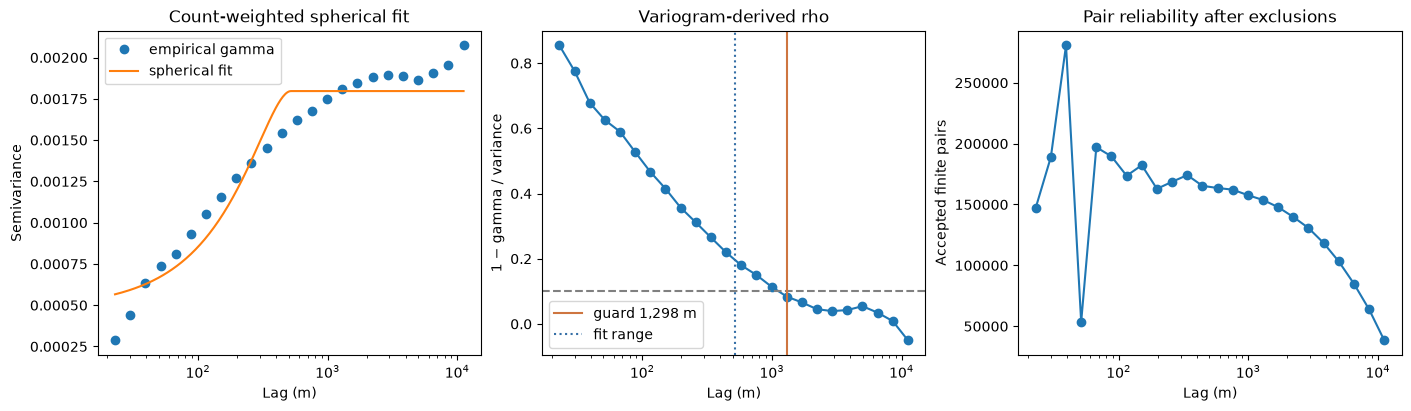

In [6]:
from core import spherical_variogram
centers=np.asarray(evaluation["lag_centers_m"],dtype=float)
gamma=np.asarray([np.nan if x is None else x for x in evaluation["gamma"]])
rho=np.asarray([np.nan if x is None else x for x in evaluation["rho"]])
fig,axes=plt.subplots(1,3,figsize=(14,4),layout="constrained")
axes[0].semilogx(centers,gamma,"o",label="empirical gamma")
model_lags=np.geomspace(centers[0],centers[-1],300)
axes[0].semilogx(model_lags,spherical_variogram(model_lags,evaluation["nugget"],
    evaluation["partial_sill"],evaluation["practical_range_m"]),label="spherical fit")
axes[0].set(xlabel="Lag (m)",ylabel="Semivariance",title="Count-weighted spherical fit")
axes[0].legend()
axes[1].semilogx(centers,rho,"o-")
axes[1].axhline(.1,color="gray",linestyle="--")
axes[1].axvline(LAG_M,color="#ce7540",label=f"guard {LAG_M:,.0f} m")
axes[1].axvline(evaluation["practical_range_m"],color="#356fa6",linestyle=":",label="fit range")
axes[1].set(xlabel="Lag (m)",ylabel="1 − gamma / variance",title="Variogram-derived rho")
axes[1].legend()
axes[2].semilogx(centers,evaluation["counts"],"o-")
axes[2].set(xlabel="Lag (m)",ylabel="Accepted finite pairs",title="Pair reliability after exclusions")
plt.show()


## Simple segmentation model and training controls

The model has three 3 × 3 convolutional layers with 16 channels and ReLU, then a 1 × 1 convolution producing three class logits (**5,283 trainable parameters**). It is trained from scratch on CPU with AdamW, learning rate 0.003, weight decay 0.0001, batch size 8, and 32 × 32 crops for 150 optimizer steps. Each crop stays inside a training rectangle. All conditions start from the same seed-42 weights and use the same training budget.

Normalization is fitted separately on each condition's finite, labelled **training pixels only**. Validation is checked every 25 steps; the highest validation mean IoU selects the checkpoint, with the earliest tie. Each selected model is then tested once on the shared held-out test pixels. Class identities and model scores are not used to choose patch geometry or the variogram buffer; source-availability masks are already part of the cached input validity. There is no class weighting, pretrained model, test-set tuning or score-dependent buffer search.


<IPython.core.display.JSON object>

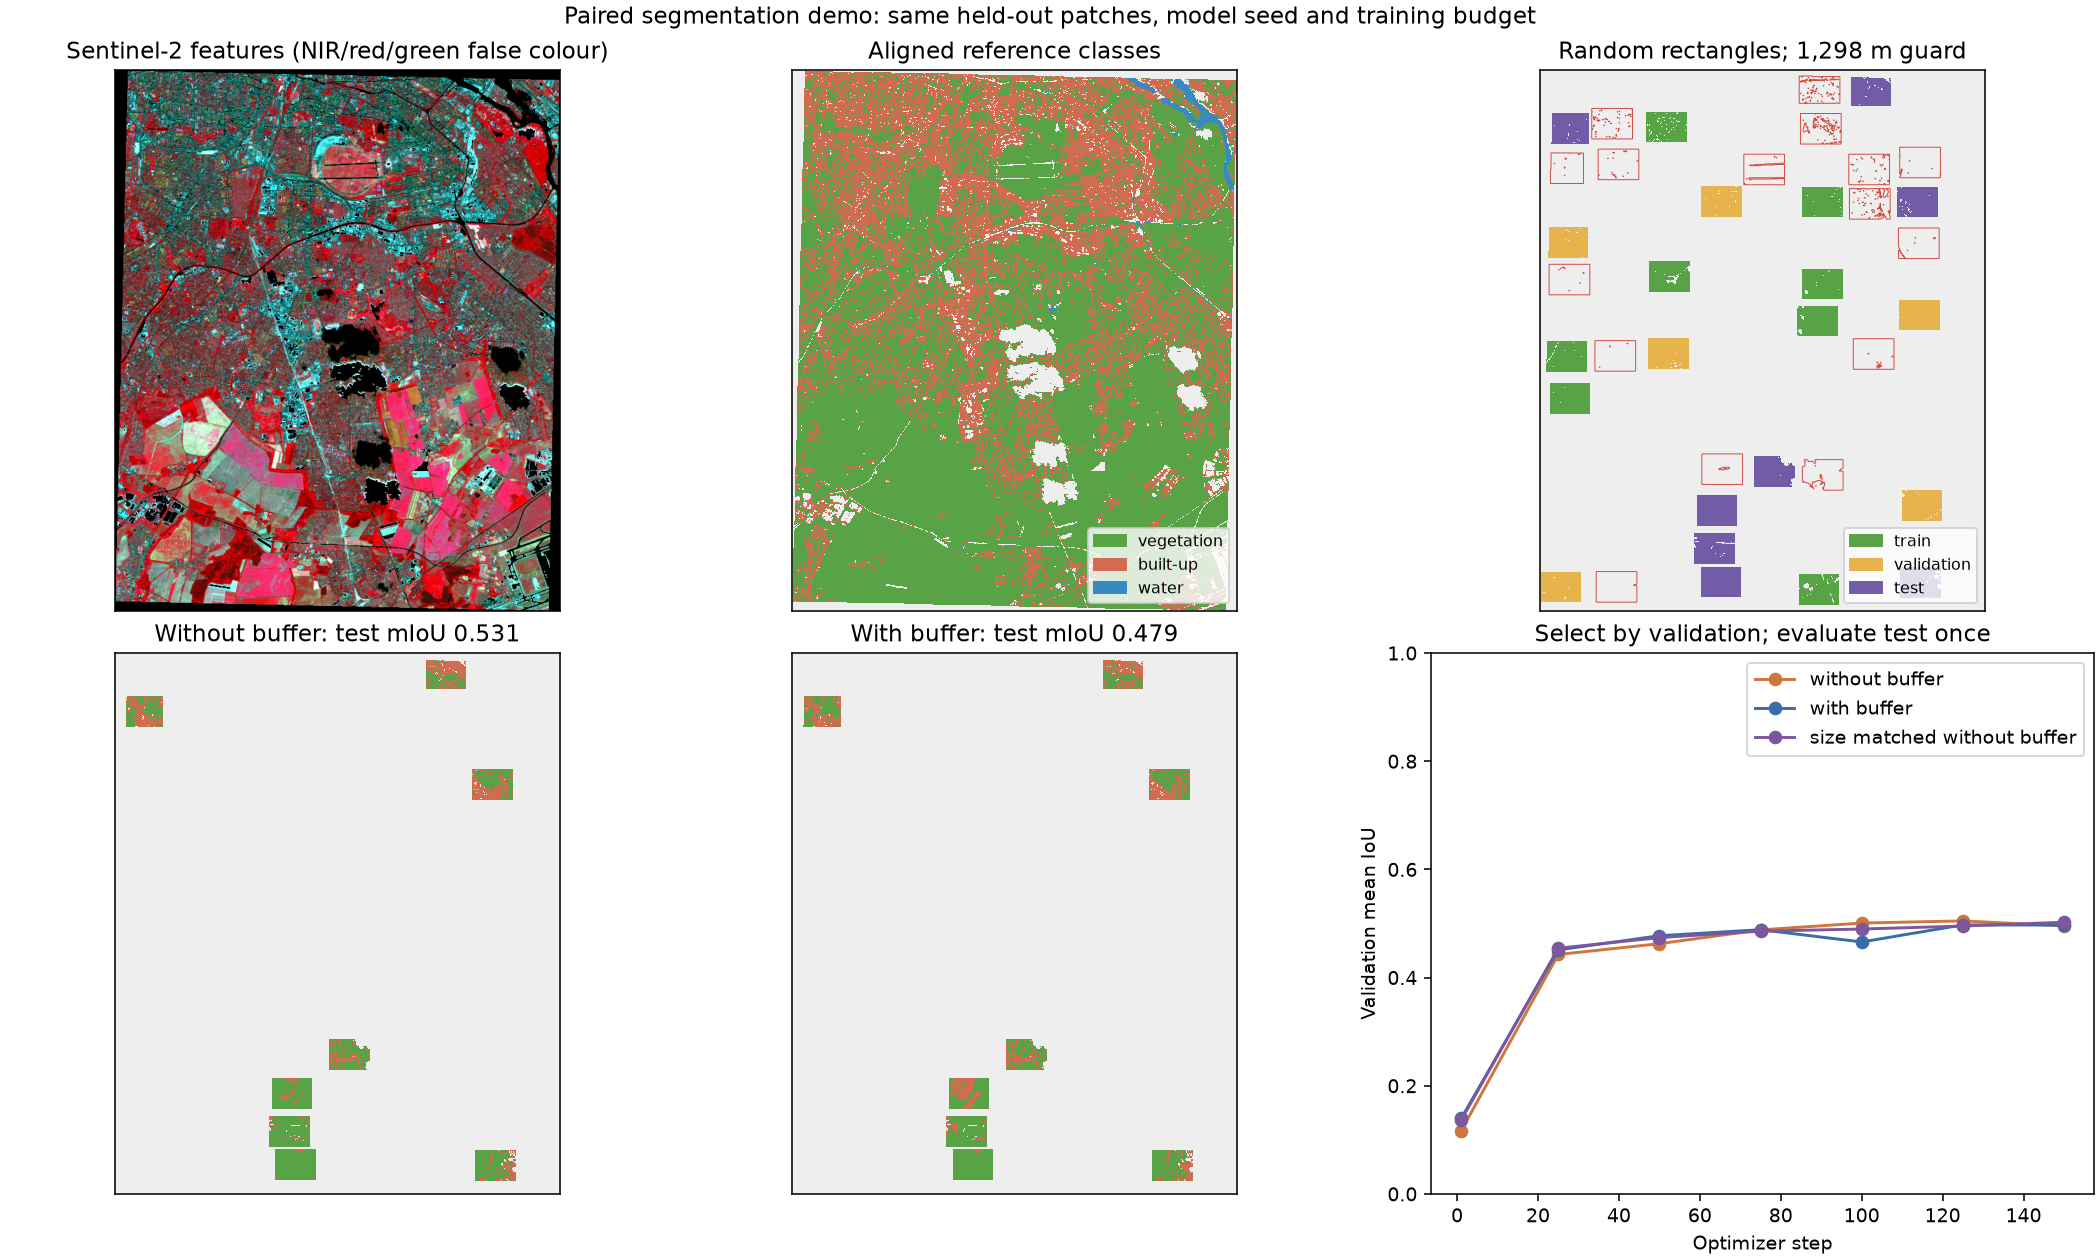

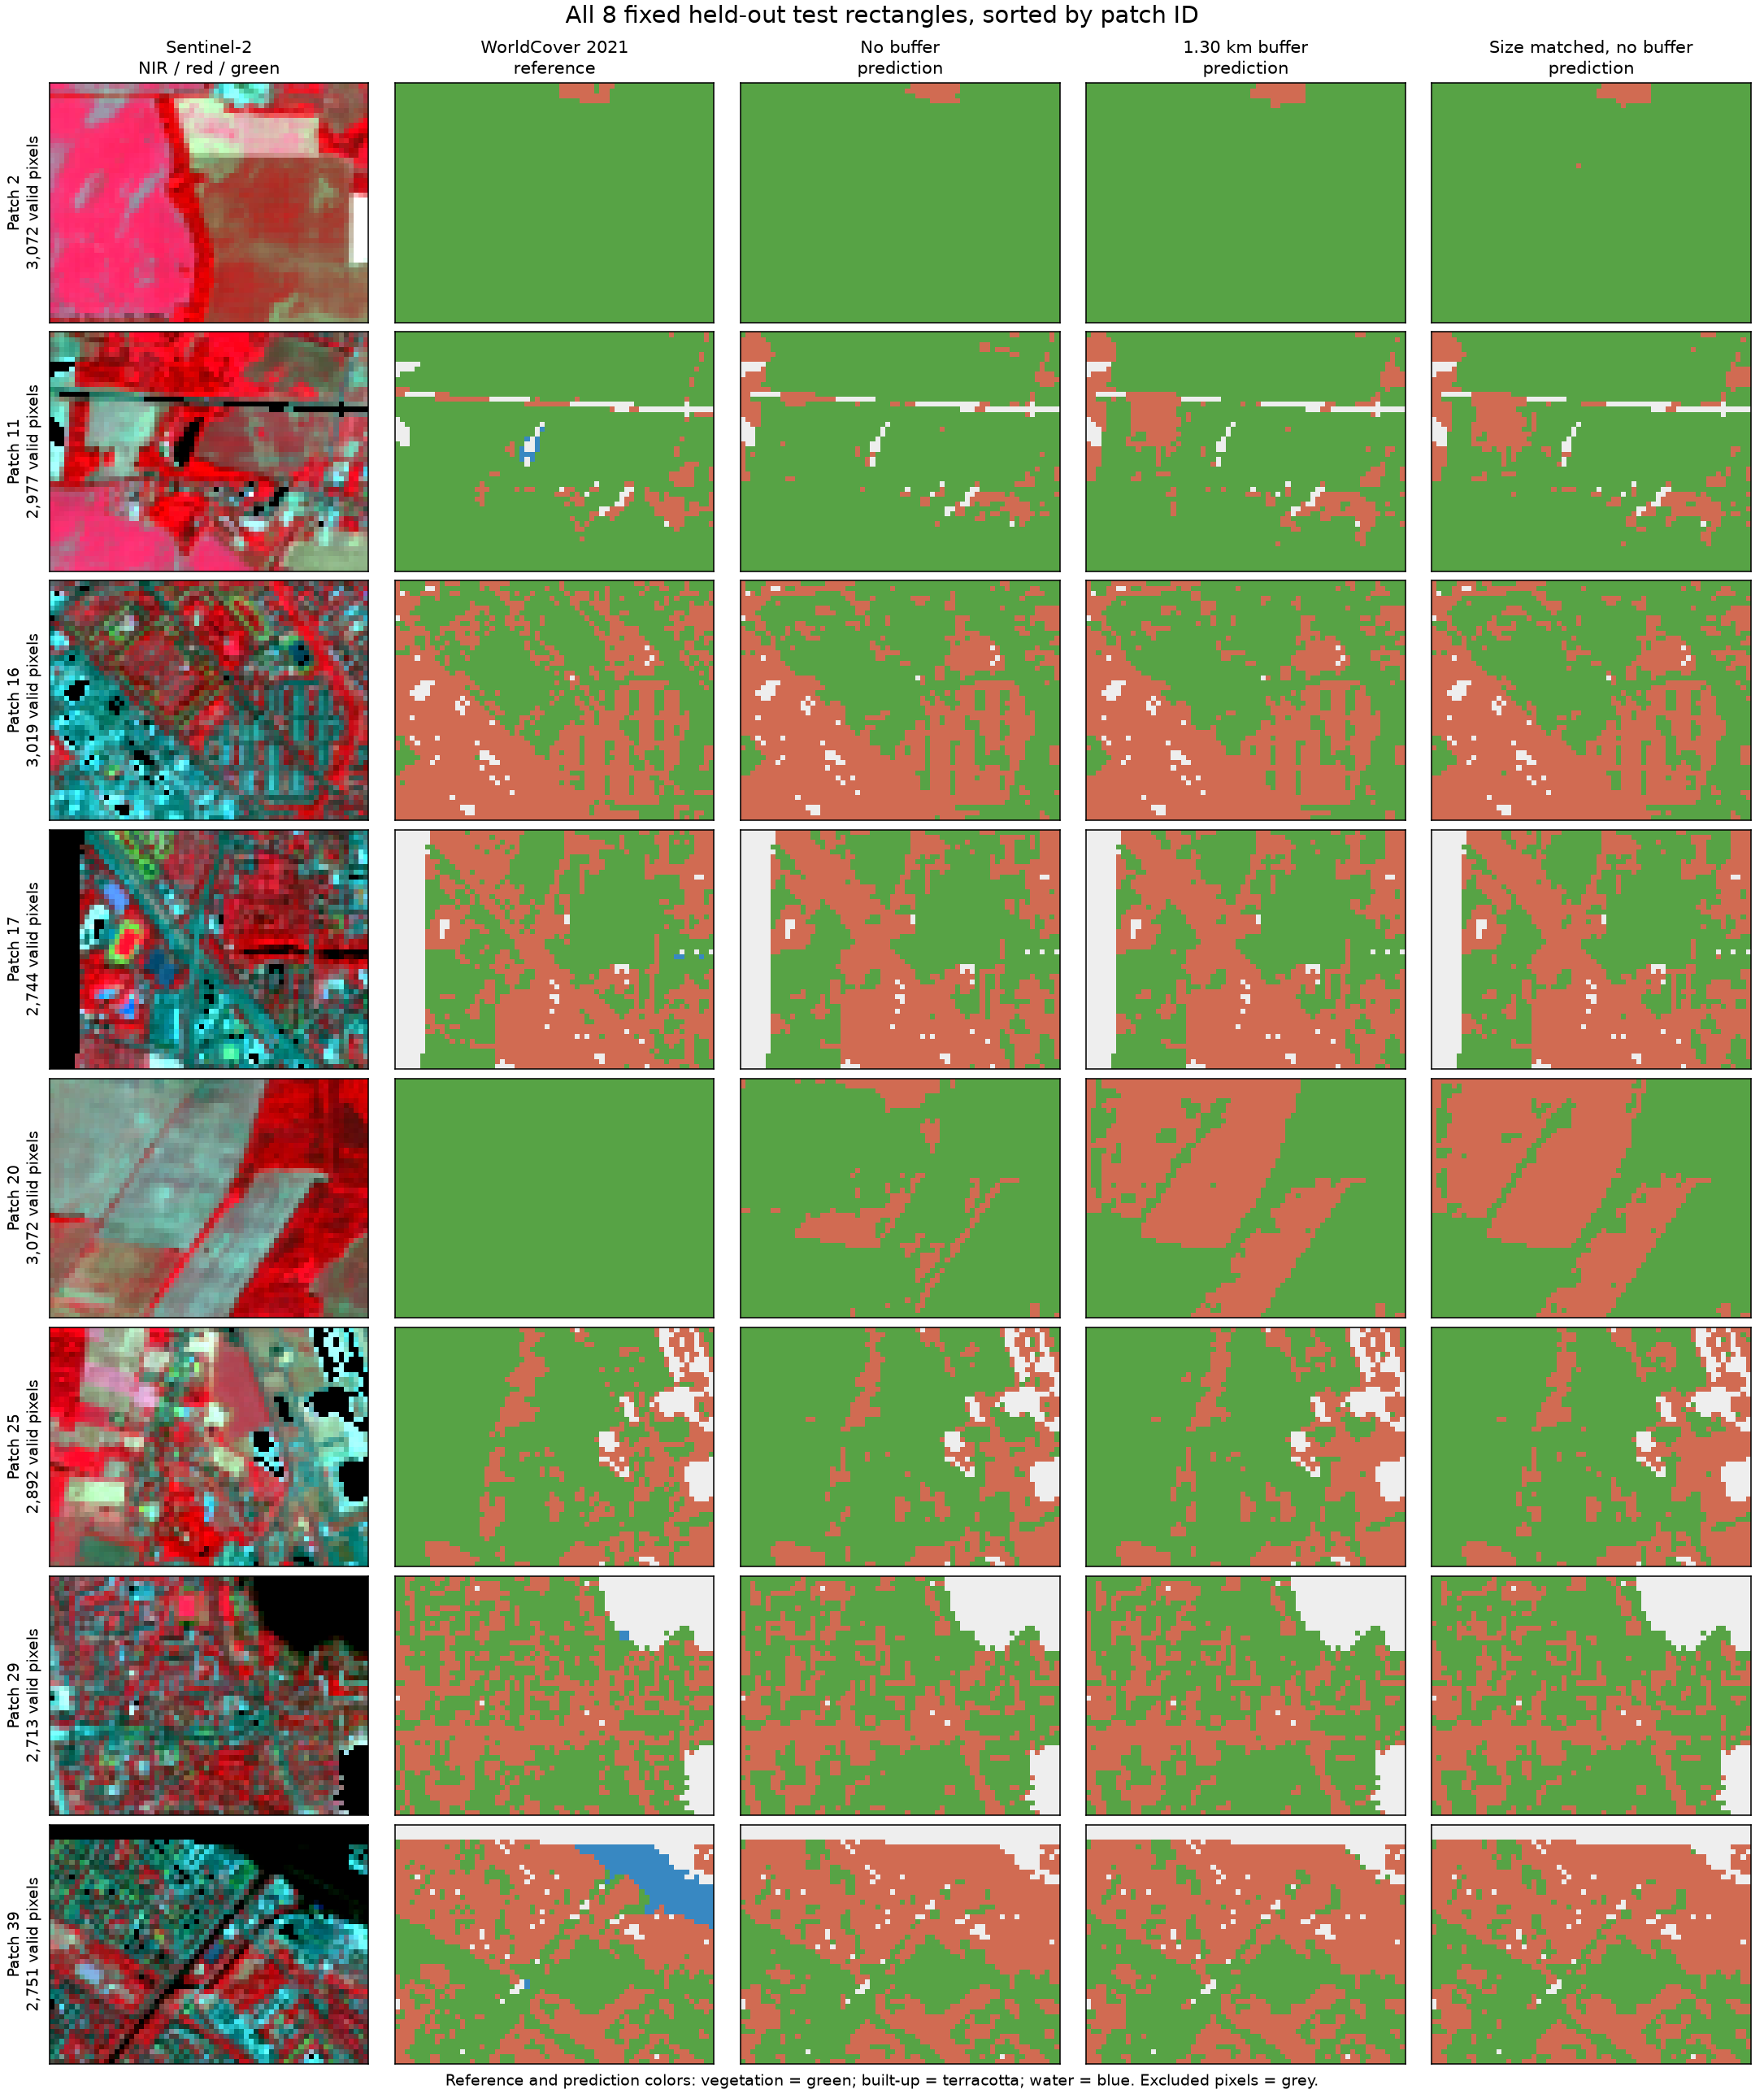

In [7]:
display(JSON({"model":segmentation_report["model"],"controls":segmentation_report["controls"],
              "label_provenance":segmentation_report["label_provenance"],
              "training_seconds":segmentation_report["elapsed_seconds"]}))
display(Image(filename=str(BENCHMARK_DIR / segmentation_report["artifacts"]["comparison"])))

if "test_patch_montage" in segmentation_report["artifacts"]:
    display(Image(filename=str(BENCHMARK_DIR / segmentation_report["artifacts"]["test_patch_montage"])))


## Observed scores, per-class IoU and separation

The table reports actual trained models on identical held-out locations. The first two rows are the requested comparison. The size-matched control helps expose the training-volume confound; it does not isolate every difference in class mix or spatial support. A lower buffered score can be an honest consequence of removing nearby training data and reducing the training pool.


In [8]:
conditions=segmentation_report["conditions"]
rows=["| Condition | Train patches | Labelled train pixels | Test mIoU | Test accuracy | Min train–test patch-edge gap (m) |",
      "| --- | ---: | ---: | ---: | ---: | ---: |"]
for name,result in conditions.items():
    rows.append(f"| {name.replace('_',' ')} | {result['training_patch_count']} | {result['training_labelled_pixel_count']:,} | "
                f"{result['test']['mean_iou']:.4f} | {result['test']['pixel_accuracy']:.4f} | "
                f"{result['minimum_train_test_patch_edge_distance_m']:.1f} |")
display(Markdown("\n".join(rows)))
class_rows=["| Class | Test reference pixels | "+" | ".join(name.replace('_',' ') for name in conditions)+" |",
            "| --- | ---: | "+" | ".join("---:" for _ in conditions)+" |"]
for i,name in enumerate(segmentation_report["class_names"]):
    class_rows.append(f"| {name} | {conditions['without_buffer']['test']['reference_class_counts'][i]:,} | "+
        " | ".join("missing" if result['test']['per_class_iou'][i] is None else f"{result['test']['per_class_iou'][i]:.4f}"
                   for result in conditions.values())+" |")
display(Markdown("\n".join(class_rows)))
display(JSON({"retained_training_labelled_fraction":segmentation_report["retained_training_labelled_fraction"],
              "conditions":{name:{key:result[key] for key in (
                  "selected_step","selected_validation_mean_iou","labelled_class_counts",
                  "minimum_train_validation_patch_edge_distance_m","minimum_train_test_patch_edge_distance_m","test")}
                  for name,result in conditions.items()},
              "interpretation":segmentation_report["interpretation"]}))


| Condition | Train patches | Labelled train pixels | Test mIoU | Test accuracy | Min train–test patch-edge gap (m) |
| --- | ---: | ---: | ---: | ---: | ---: |
| without buffer | 24 | 70,237 | 0.5307 | 0.9016 | 100.0 |
| with buffer | 8 | 23,845 | 0.4790 | 0.8519 | 1700.0 |
| size matched without buffer | 8 | 23,326 | 0.4785 | 0.8515 | 220.0 |

| Class | Test reference pixels | without buffer | with buffer | size matched without buffer |
| --- | ---: | ---: | ---: | ---: |
| vegetation | 16,424 | 0.8810 | 0.8135 | 0.8134 |
| built-up | 6,587 | 0.7111 | 0.6235 | 0.6222 |
| water | 229 | 0.0000 | 0.0000 | 0.0000 |

<IPython.core.display.JSON object>

The measured buffer increases separation and removes whole training patches. In the recorded experiment, the full 24-patch unbuffered model scores higher than the 8-patch buffered model, while the 8-patch size-matched control is close to the buffered result. **The score gap cannot be attributed to leakage alone.** Water has only 229 test pixels and very few training pixels; all conditions fail to predict it in this run. Per-class results expose this weakness even when overall pixel accuracy looks high.

One AOI, one acquisition and one split/model seed provide a demonstration, not an estimate of generalization uncertainty. Repeat across seeds, regions and seasons; use independent labels and stratification suitable for the application. The WorldCover-derived scores are reference-map agreement, not field-validated accuracy. A buffer is an evaluation-design choice and does not guarantee higher segmentation accuracy.


## MCP tool contract

Four tools expose the measurements and patch planning: `evaluate_sentinel2_autocorrelation`, `evaluate_spatial_autocorrelation`, `plan_sentinel2_split`, and `plan_spatial_split`. Planning accepts `patch_size_pixels=[48,64]` and `n_patches=40`, exports buffered and paired unbuffered masks plus patch-coordinate/keep records, and reports retention and actual cross-split distances. Mask values are `0=excluded`, `1=train`, `2=validation`, `3=test`.

The optional model runner is separate from the MCP server, so PyTorch is not required to serve the four tools. The cell below discovers the real MCP schemas and plans the same random rectangles through `tools/call` on the actual 2021 raster. Artifact paths refer to the MCP server filesystem.


In [9]:
from mcp import ClientSession
from mcp.client.stdio import StdioServerParameters,stdio_client
server_parameters=StdioServerParameters(command=sys.executable,
    args=[str(TOOL_ROOT / "server.py"),"--transport","stdio"])
async with stdio_client(server_parameters) as (read,write):
    async with ClientSession(read,write) as session:
        await session.initialize()
        tools=await session.list_tools()
        display(JSON({tool.name:tool.inputSchema for tool in tools.tools}))
        result=await session.call_tool("plan_spatial_split",{
            "raster_path":str(feature_path),"band_index":1,"buffer_m":LAG_M,"lag_m":LAG_M,
            "patch_size_pixels":PATCH_SIZE_PIXELS,"n_patches":N_PATCHES,
            "seed":SPLIT_SEED,**VARIOGRAM_OPTIONS})
        if result.isError: raise RuntimeError(result)
        mcp_plan=json.loads(next(block.text for block in result.content if block.type=="text"))
        if mcp_plan.get("status")!="ok": raise RuntimeError(mcp_plan)
        display(JSON({key:mcp_plan[key] for key in (
            "schema_version","method","patch_size_pixels","n_candidate_patches","patch_counts",
            "paired_comparison","buffer_autocorrelation","splits","spatial_diagnostics","artifacts")
            if key in mcp_plan}))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## Could EVE obtain imagery through GIS MCP?

**Yes, conditionally.** The documented [`download_satellite_imagery`](https://gis-mcp.com/data-gathering/satellite_imagery/) tool can return a numeric GeoTIFF path for Sentinel-2. A deployed GIS MCP server must first be registered with EVE; the documentation URL is not a tool endpoint. The inspected EVE account has no GIS MCP server enabled, so **GIS acquisition has not been tested here**. Actual imagery in this notebook comes from public Planetary Computer STAC through this project's reader.

Request B05 plus SCL on their common 20 m grid, verify the actual returned scene/date/assets, crop to the AOI, apply processing-baseline reflectance calibration and SCL cloud/shadow/nodata masking, and preserve a projected metre grid. The audited GIS writer does not apply radiometric calibration or preserve scale/offset metadata. It cannot directly stack 10 m B03/B04/B08 with 20 m B05/SCL: align the extra bands separately. Search fallbacks can relax constraints, and scene cloud percentage is not an AOI mask.

Transfer the resulting file or use shared storage before handing its path to `evaluate_spatial_autocorrelation` and `plan_spatial_split`. A path local to the GIS server is not automatically readable by the planner. The source-audited contract below records these requirements and the transport/download route; it is not evidence of an executed GIS integration.


In [10]:
gis_contract_path=ARTIFACTS / "gis_mcp_contract.json"
if gis_contract_path.exists():
    display(JSON(json.loads(gis_contract_path.read_text())))


<IPython.core.display.JSON object>

## Reference parity and live EVE evidence

The reference artifact compares the variogram calculations with frozen checkpoint `ac7dfc6`. Gateway discovery documents the actual enabled EVE services. The model/tool trace and machine-computed reports must identify their schema and geometry version: an older successful run does not validate revised patch behavior. The live MCP replay can use the separately recorded 2024 B05 scene; the matched-year 2021 segmentation experiment above is a distinct local CPU run.

The summary displays verification flags and any human review notes. Model prose can misstate numbers or overclaim leakage prevention; the numeric reports and geometry checks govern interpretation. No diagnostic proves label independence, independence in all other bands, or temporal transferability.


In [11]:
for filename in ("reference_validation.json","eve_gateway_discovery.json","eve_demo.json"):
    evidence_path=ARTIFACTS / filename
    if not evidence_path.exists():
        print(f"No saved evidence: {filename}")
        continue
    evidence=json.loads(evidence_path.read_text())
    if filename=="reference_validation.json":
        display(JSON(evidence))
    elif filename=="eve_gateway_discovery.json":
        display(JSON({"file":filename,**{key:evidence[key] for key in (
            "tested_at_utc","imagery_access_note","sentinel2_discovery_calls") if key in evidence}}))
    else:
        display(JSON({"file":filename,**{key:evidence[key] for key in (
            "tested_at_utc","model","servers","available_tool_names","verification",
            "configuration_source","review_notes") if key in evidence}}))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## Scientific limits

Approximate **stationarity and isotropy** are assumed. Uniform angles average directional structure away. Pair differencing removes dependence on an arbitrary constant mean but **does not remove spatial trend**: trend can affect both gamma and global variance, and therefore rho. Inspect the fit, accepted pair counts and AOI structure before relying on the range. Cloud exclusions can bias the sampled subset.

Use continuous fields for the variogram. Arbitrary categorical class codes have no meaningful numeric variance; per-class indicators are possible separate analyses. The B05-derived buffer does not establish that all other bands or labels share the same spatial range. Random rectangle selection and buffer exclusions change training composition, and this demonstration does not guarantee balanced classes or operational model quality.
